# Demo 4 — QSVT cho bài toán dữ liệu lớn
**Người nói 3 · 35:10–37:10 (2 phút)**

Ba cell chạy trực tiếp, mỗi cell dưới vài giây. Mức phân tích: áp đa thức lên ma trận bằng numpy, đúng như khối trên-trái của mạch QSVT.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qsvt_demo import *
import qsvt_demo

plt.rcParams.update({"font.size": 13, "figure.figsize": (8, 3.6), "axes.grid": True})
reset_rng()
print(f"Qiskit {qiskit.__version__} | numpy {np.__version__} | seed {SEED}")
import csv

def read_csv(name):
    with open(DATA / name, encoding="utf-8") as fh:
        rows = list(csv.DictReader(fh))
    return {k: np.array([r[k] for r in rows]) for k in rows[0]}

Qiskit 2.6.2 | numpy 2.5.5 | seed 1234


## Cell 2 — E10: hồi quy tuyến tính bằng nghịch đảo giả
Ma trận dữ liệu X (12 mẫu × 4 đặc trưng, κ = 4) không vuông, nên nhúng vào H = [[0, X], [Xᵀ, 0]] (16×16, tức 4 qubit + 1 ancilla). Áp 1/x làm trơn (hàm lẻ, g(0) = 0) lên H: khối dưới của g(H)[y; 0] tỉ lệ với β = X⁺y.

In [2]:
reset_rng()
kappa, n, d = 4, 12, 4
X = matrix_with_singular_values(n, d, np.geomspace(1, 1 / kappa, d))
beta_true = rng.normal(size=d)
y = X @ beta_true + 0.05 * rng.normal(size=n); y /= np.linalg.norm(y)
g = g_inv(kappa)
deg = min_degree(g, 1e-3)
out = f_of_A(cheb_poly(g, deg), hermitian_dilation(X)) @ np.concatenate([y, np.zeros(d)])
beta_q = 2 * kappa * out[n:]
beta_c = np.linalg.lstsq(X, y, rcond=None)[0]
rel = np.linalg.norm(beta_q - beta_c) / np.linalg.norm(beta_c)
print(f"bậc đa thức = {deg}, max|g| = {check_bounded(g):.3f}")
print("β QSVT :", np.round(beta_q, 4))
print("β lstsq:", np.round(beta_c, 4))
print(f"sai số tương đối = {rel:.2e}, xác suất hậu chọn = {np.linalg.norm(out)**2:.4f}", verdict(rel < 1e-2))

bậc đa thức = 53, max|g| = 0.957
β QSVT : [-1.2095  0.0504  0.5808  0.1894]
β lstsq: [-1.2098  0.0506  0.5782  0.1908]
sai số tương đối = 2.21e-03, xác suất hậu chọn = 0.0287 PASS


## Cell 3 — E11: PCA bằng lọc giá trị kỳ dị
X 16×16 có 2 thành phần chính (σ = 0,95; 0,8) và nhiễu σ ≤ 0,25. Đa thức chẵn xấp xỉ hàm bước tại τ = 0,5 cho projector lên 2 thành phần đó. Khe hở δ càng hẹp, bậc càng cao.

δ = 0.3   bậc =  16   bậc × δ =  4.8   sai số projector = 4.5e-03
δ = 0.2   bậc =  26   bậc × δ =  5.2   sai số projector = 4.4e-03
δ = 0.1   bậc =  50   bậc × δ =  5.0   sai số projector = 4.2e-03
δ = 0.05  bậc =  95   bậc × δ =  4.8   sai số projector = 3.5e-03


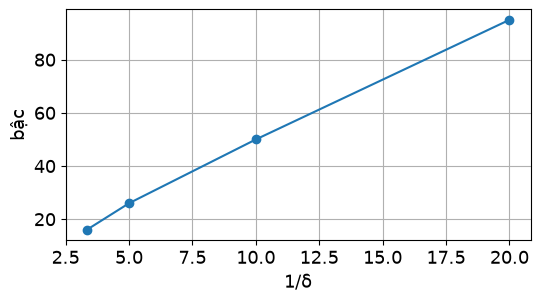

PASS


In [3]:
reset_rng()
svals = np.concatenate([[0.95, 0.8], rng.uniform(0, 0.25, 14)])
X = matrix_with_singular_values(16, 16, svals)
_, _, Vt = np.linalg.svd(X); P_true = Vt[:2].T @ Vt[:2]
deltas, degs = [0.3, 0.2, 0.1, 0.05], []
for delta in deltas:
    f = smooth_step(0.5, delta)
    dg = min_degree(f, 1e-2); degs.append(dg)
    P = f_of_A(cheb_poly(f, dg), hermitian_dilation(X))[16:, 16:]
    print(f"δ = {delta:<5} bậc = {dg:>3}   bậc × δ = {dg * delta:4.1f}   sai số projector = {np.linalg.norm(P - P_true, 2):.1e}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(1 / np.array(deltas), degs, "o-"); ax.set_xlabel("1/δ"); ax.set_ylabel("bậc"); plt.show()
prod = [dg * dl for dg, dl in zip(degs, deltas)]
print(verdict(max(prod) / min(prod) < 1.5))

## Cell 4 — E12: cái giá của việc nạp dữ liệu
Block-encoding dựng từ QRAM có hệ số chuẩn hóa ‖A‖_F thay vì ‖A‖, nên số truy vấn bị nhân với ‖A‖_F/‖A‖. Ma trận đầy đủ hạng: tỉ lệ tăng theo √N; hạng thấp k: không quá √k.

In [4]:
reset_rng()
for N in (256, 512, 1024):
    full = rng.normal(size=(N, N))
    low = rng.normal(size=(N, 5)) @ rng.normal(size=(5, N))
    r_full = np.linalg.norm(full, "fro") / np.linalg.norm(full, 2)
    r_low = np.linalg.norm(low, "fro") / np.linalg.norm(low, 2)
    print(f"N = {N:>4}: đầy đủ hạng {r_full:5.2f} (√N/2 = {np.sqrt(N)/2:4.1f})   hạng 5 {r_low:4.2f} (≤ √5 = {np.sqrt(5):.2f})")
print(verdict(r_low <= np.sqrt(5) + 1e-9))

N =  256: đầy đủ hạng  8.05 (√N/2 =  8.0)   hạng 5 1.98 (≤ √5 = 2.24)
N =  512: đầy đủ hạng 11.51 (√N/2 = 11.3)   hạng 5 2.02 (≤ √5 = 2.24)


N = 1024: đầy đủ hạng 16.09 (√N/2 = 16.0)   hạng 5 2.11 (≤ √5 = 2.24)
PASS


## Cell 5 — Dự phòng
Nếu máy chậm: đọc kết quả đã tính sẵn bằng `scripts/make_data.py`.

In [5]:
for name in ["e10_regression.csv", "e11_pca_degrees.csv", "e12_frobenius_ratio.csv"]:
    t = read_csv(name)
    print(name)
    print("  " + " | ".join(t))
    for r in zip(*t.values()):
        print("  " + " | ".join(r))

e10_regression.csv
  kappa | n | d | dilation_dim | degree | rel_error | p_success
  2 | 12 | 4 | 16 | 27 | 2.09e-03 | 0.0657
  4 | 12 | 4 | 16 | 53 | 2.35e-03 | 0.0759
  8 | 12 | 4 | 16 | 107 | 2.00e-03 | 0.0137
e11_pca_degrees.csv
  delta | degree | degree_x_delta | projector_error
  0.3 | 16 | 4.8 | 4.48e-03
  0.2 | 26 | 5.2 | 4.40e-03
  0.1 | 50 | 5.0 | 4.16e-03
  0.05 | 95 | 4.8 | 3.90e-03
e12_frobenius_ratio.csv
  N | matrix | fro_over_spectral | reference
  256 | full rank | 8.04 | 8.0
  256 | rank 5 | 1.99 | 2.24
  512 | full rank | 11.49 | 11.3
  512 | rank 5 | 2.02 | 2.24
  1024 | full rank | 16.05 | 16.0
  1024 | rank 5 | 2.11 | 2.24
